# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture06_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


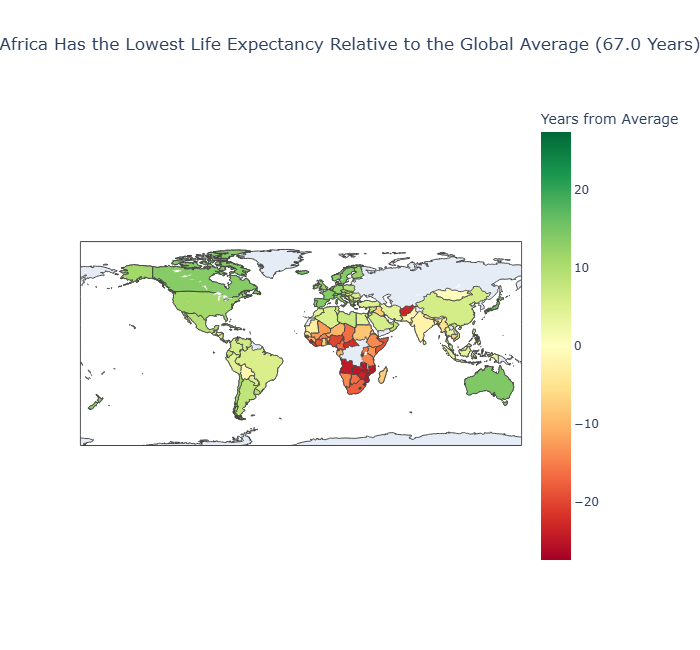

In [9]:
# Task 1
# Load Gapminder data for 2007
gm = px.data.gapminder()
gm_2007 = gm[gm['year'] == 2007].copy()

# Calculate global average life expectancy
global_mean = gm_2007['lifeExp'].mean()

# Calculate each country's difference from the global average
gm_2007['lifeExp_deviation'] = gm_2007['lifeExp'] - global_mean

# Find the continent furthest below the global average
continent_deviation = (
    gm_2007.groupby('continent')['lifeExp_deviation']
    .mean()
    .sort_values()
)

lowest_continent = continent_deviation.index[0]

# Create the world choropleth
fig = px.choropleth(
    gm_2007,
    locations='country',
    locationmode='country names',
    color='lifeExp_deviation',
    hover_name='country',
    hover_data={
        'lifeExp': ':.2f',
        'lifeExp_deviation': ':+.2f',
        'country': False
    },
    color_continuous_scale='RdYlGn',
    color_continuous_midpoint=0,
    title=(
        f'{lowest_continent} Has the Lowest Life Expectancy '
        f'Relative to the Global Average ({global_mean:.1f} Years)'
    ),
    labels={
        'lifeExp': 'Life Expectancy (Years)',
        'lifeExp_deviation': 'Difference from Global Average (Years)'
    }
)

fig.update_layout(
    title_x=0.5,
    height=650,
    coloraxis_colorbar_title='Years from Average'
)

fig.show(renderer="png")


## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** *(URL or description)*

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

*Your answer here*

**Colour scale chosen** (sequential or diverging) **and reason:**

*Your answer here*


In [4]:
# Task 2
# YOUR CODE HERE


# Task 2 — Population density across German states

import urllib.request

# Load German state boundaries
geojson_url = (
    "https://raw.githubusercontent.com/isellsoap/"
    "deutschlandGeoJSON/main/2_bundeslaender/4_niedrig.geo.json"
)

with urllib.request.urlopen(geojson_url) as response:
    my_geojson = json.loads(response.read().decode("utf-8"))

# Inspect GeoJSON properties
print(my_geojson['features'][0]['properties'])


{'id': 'DE-BW', 'name': 'Baden-Württemberg', 'type': 'State'}


In [5]:

# Population density data for German federal states (2023)
population_data = {
    'id': [
        'DE-BW', 'DE-BY', 'DE-BE', 'DE-BB',
        'DE-HB', 'DE-HH', 'DE-HE', 'DE-MV',
        'DE-NI', 'DE-NW', 'DE-RP', 'DE-SL',
        'DE-SN', 'DE-ST', 'DE-SH', 'DE-TH'
    ],
    'state': [
        'Baden-Württemberg', 'Bavaria', 'Berlin', 'Brandenburg',
        'Bremen', 'Hamburg', 'Hesse', 'Mecklenburg-Vorpommern',
        'Lower Saxony', 'North Rhine-Westphalia', 'Rhineland-Palatinate',
        'Saarland', 'Saxony', 'Saxony-Anhalt', 'Schleswig-Holstein',
        'Thuringia'
    ],
    'density': [
        312, 188, 4210, 88,
        1630, 2515, 299, 69,
        168, 529, 207, 386,
        231, 106, 185, 130
    ]
}

density_df = pd.DataFrame(population_data)

density_df.head()


,id,state,density
0,DE-BW,Baden-Württemberg,312
1,DE-BY,Bavaria,188
2,DE-BE,Berlin,4210
3,DE-BB,Brandenburg,88
4,DE-HB,Bremen,1630


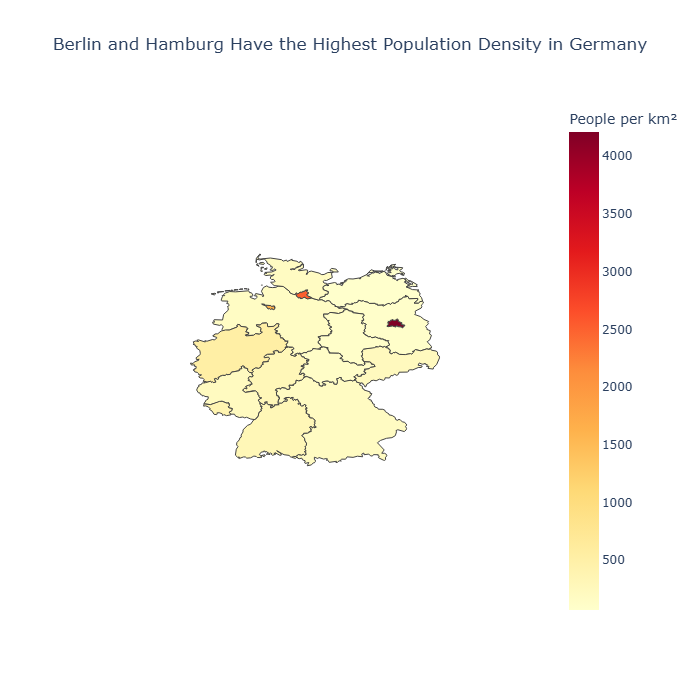

In [7]:

# Create the choropleth map
fig = px.choropleth(
    density_df,
    geojson=my_geojson,
    locations='id',
    featureidkey='properties.id',
    color='density',
    hover_name='state',
    hover_data={'density': True, 'id': False},
    color_continuous_scale='YlOrRd',
    title='Berlin and Hamburg Have the Highest Population Density in Germany',
    labels={'density': 'People per km²'}
)

fig.update_geos(fitbounds='locations', visible=False)

fig.update_layout(
    title_x=0.5,
    height=700,
    coloraxis_colorbar_title='People per km²'
)

fig.show(renderer="png")
